#### The travelling fKdV wave 

In this notebook a travelling wave profile is created and then solved forward in time

In [49]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

In [50]:
from solvers.spectral import fKdVNewton
from solvers.pde import fKdV
from solvers.lsm import LSM
from solvers.help import *

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt


In [51]:
P           = 4* np.pi
target_amp  = 1
mean        = 1
alpha       = 2

N           = 2**6

In [52]:
twave = fKdVNewton(P=P, target_amp=target_amp, mean= mean, N = N, alpha=alpha)
twave.solve_w_continuation(n_steps=50)

amplitude = 1.0804279972043833
Wave speed c = 0.9209458739112647
Constant B = -0.14439437031757701


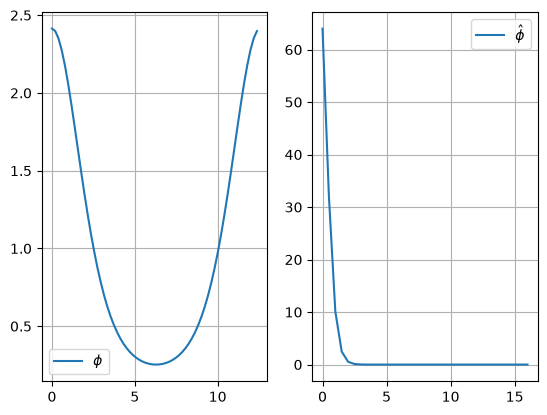

In [53]:
twave._plot_()

### Then solving it forward in time

In [54]:
dt  = 5e-3
T   = 3
#As the Spectral solver workes only on the positive part of the spectrum due to symmetry
u0 = np.fft.irfft(twave.phi_hat)

fwave = fKdV(P=P, dt =dt , T=T, u0=u0 , alpha=alpha)
t, u = fwave.splitStep()


In [55]:
x = np.linspace(0,P,N)
animate_solution_nb(x,u, stride=2)